# Uczenie maszynowe 1
## Pracownia specjalistyczna nr 4
### Selekcja cech – metody filtracyjne

## Cele zajęć

Po wykonaniu ćwiczeń student powinien potrafić:

- wyjaśnić cel selekcji cech,
- rozpoznać cechę stałą i prawie stałą,
- wyjaśnić wpływ skali na wariancję,
- wskazać cechy redundantne na podstawie korelacji,
- wykorzystać Mutual Information,
- zastosować test chi-kwadrat dla cechy jakościowej,
- dobrać test dla dwóch klas: test t-Studenta, test t Welcha lub test U Manna–Whitneya,
- dobrać test dla więcej niż dwóch klas: ANOVA lub test Kruskala–Wallisa,
- pamiętać, że selekcję cech dopasowujemy wyłącznie na danych treningowych.

## 1. Import bibliotek


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    shapiro,
    levene,
    ttest_ind,
    mannwhitneyu,
    f_oneway,
    kruskal,
    chi2_contingency
)

from sklearn.feature_selection import (
    VarianceThreshold,
    mutual_info_classif
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from statsmodels.stats.multicomp import pairwise_tukeyhsd

## 2. Odczyt danych


In [3]:
df = pd.read_csv("selekcja_cech_pracownia4.csv")

print("Rozmiar zbioru:", df.shape)
df.head()

Rozmiar zbioru: (180, 20)


,id,segment,wiek,wynik_oceny,czas_obslugi_min,dochod_mies_pln,wydatki_mies_pln,wydatki_roczne_pln,wizyty_mies,wizyty_kwartal,czas_na_stronie_min,satysfakcja,sygnal_nieliniowy,losowa_numeryczna,losowa_numeryczna_2,cecha_stala,cecha_prawie_stala,program_lojalnosci,kanal,losowa_kategoria
0,1,A,35.8,49.4,17.4,4571.45,545.62,6421.35,5,16,1.02,6.2,4.60,-1.958,-0.223,1,1,nie,WWW,Z
1,2,A,30.2,59.0,17.5,4007.61,637.09,7244.59,2,4,0.17,6.0,6.27,-1.466,-0.032,1,1,nie,WWW,Y
2,3,A,38.3,66.6,15.9,2919.70,439.83,5302.49,2,7,4.71,6.9,5.60,0.283,-0.547,1,1,nie,WWW,Y
3,4,A,41.1,55.5,17.5,7608.28,802.70,8933.49,6,16,0.46,6.8,4.99,1.138,-0.192,1,0,nie,WWW,Z
4,5,A,40.1,59.6,18.6,3569.69,558.47,6366.38,2,8,0.77,5.1,4.68,0.618,0.302,1,1,nie,WWW,X


## 3. Opis najważniejszych atrybutów

| Atrybut | Znaczenie |
|---|---|
| `segment` | klasa docelowa: A, B lub C |
| `wiek` | wiek klienta |
| `wynik_oceny` | syntetyczny wynik punktowy klienta |
| `czas_obslugi_min` | czas obsługi klienta w minutach |
| `dochod_mies_pln` | miesięczny dochód |
| `wydatki_mies_pln` | miesięczne wydatki |
| `wydatki_roczne_pln` | roczne wydatki; celowo silnie związane z wydatkami miesięcznymi |
| `wizyty_mies` | liczba wizyt w miesiącu |
| `wizyty_kwartal` | liczba wizyt w kwartale; celowo powiązana z `wizyty_mies` |
| `czas_na_stronie_min` | czas spędzany w serwisie; zmienna skośna |
| `satysfakcja` | ocena satysfakcji |
| `sygnal_nieliniowy` | sztuczna cecha zależna od klasy w sposób nieliniowy |
| `losowa_numeryczna`, `losowa_numeryczna_2` | cechy losowe |
| `cecha_stala` | identyczna wartość dla wszystkich obserwacji |
| `cecha_prawie_stala` | prawie zawsze ta sama wartość |
| `program_lojalnosci` | udział w programie lojalnościowym |
| `kanal` | główny kanał kontaktu / zakupu |
| `losowa_kategoria` | losowa cecha jakościowa |

Zbiór został skonstruowany tak, aby na jednym pliku można było pokazać różne sytuacje występujące podczas selekcji cech.


## 4. Podział na zbiór treningowy i testowy

Selekcja cech jest częścią przygotowania danych.  
Dlatego parametry selekcji wyznaczamy **na zbiorze treningowym**, a następnie stosujemy do danych testowych.


In [4]:
train, test = train_test_split(
    df,
    test_size=0.25,
    random_state=7,
    stratify=df["segment"]
)

print("Trening:", train.shape)
print("Test:", test.shape)

Trening: (135, 20)
Test: (45, 20)


# Część A. Wariancja


## 5. Cecha stała

Jeżeli wariancja cechy wynosi `0`, wszystkie obserwacje mają tę samą wartość.  
Taka cecha nie pozwala rozróżniać klas.

Dla `VarianceThreshold(threshold=0)` wcześniejsze skalowanie nie jest potrzebne.


In [5]:
features_var = [
    "wiek",
    "dochod_mies_pln",
    "cecha_stala"
]

print(train[features_var].var())

wiek               1.124973e+02
dochod_mies_pln    9.527681e+06
cecha_stala        0.000000e+00
dtype: float64


In [6]:
selector = VarianceThreshold(threshold=0)

selector.fit(train[features_var])

print("Pozostawione cechy:")
print(np.array(features_var)[selector.get_support()])

print("Usunięte cechy:")
print(np.array(features_var)[~selector.get_support()])

Pozostawione cechy:
['wiek' 'dochod_mies_pln']
Usunięte cechy:
['cecha_stala']


## 6. Próg wariancji większy od zera a skala cech

Wariancja zależy od jednostki i zakresu wartości.

Nie powinniśmy więc bez zastanowienia porównywać jednym progiem np.:

- wieku,
- dochodu w PLN,
- cechy binarnej 0/1.

Najpierw zobaczmy wariancje na danych surowych.


In [7]:
features_scale = [
    "wiek",
    "dochod_mies_pln",
    "cecha_prawie_stala"
]

print(train[features_scale].var())

wiek                  1.124973e+02
dochod_mies_pln       9.527681e+06
cecha_prawie_stala    1.470426e-02
dtype: float64


Jednym z możliwych rozwiązań jest sprowadzenie cech do wspólnego zakresu.  
Poniżej stosujemy `MinMaxScaler`.

Skaler jest dopasowany wyłącznie do danych treningowych.


In [8]:
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train[features_scale]
)

test_scaled = scaler.transform(
    test[features_scale]
)

train_scaled_df = pd.DataFrame(
    train_scaled,
    columns=features_scale
)

print("Wariancje po MinMaxScaler:")
print(train_scaled_df.var())

Wariancje po MinMaxScaler:
wiek                  0.055064
dochod_mies_pln       0.041349
cecha_prawie_stala    0.014704
dtype: float64


### Dlaczego nie StandardScaler?

Po standaryzacji każda niestała cecha w danych treningowych ma wariancję około `1`.  
Gdybyśmy potem chcieli wybierać cechy na podstawie różnic wariancji, utracilibyśmy informację, którą chcemy wykorzystać.

Dlatego:

- dla `threshold=0` skalowanie nie jest potrzebne,
- dla progu większego od zera trzeba uwzględnić skalę cech,
- `StandardScaler` nie jest dobrym krokiem przed porównywaniem wariancji cech.


# Część B. Korelacja i redundancja


## 7. Silnie skorelowane cechy

Sprawdźmy korelację.


In [9]:
corr = train[
    [
        "wydatki_mies_pln",
        "wydatki_roczne_pln",
        "wiek"
    ]
].corr()

corr.round(3)

,wydatki_mies_pln,wydatki_roczne_pln,wiek
wydatki_mies_pln,1.000,0.998,0.440
wydatki_roczne_pln,0.998,1.000,0.437
wiek,0.440,0.437,1.000


### Wykres punktowy

Macierz korelacji podaje wartość liczbową, ale wykres punktowy pozwala zobaczyć również **kształt zależności** i ewentualne nietypowe obserwacje.


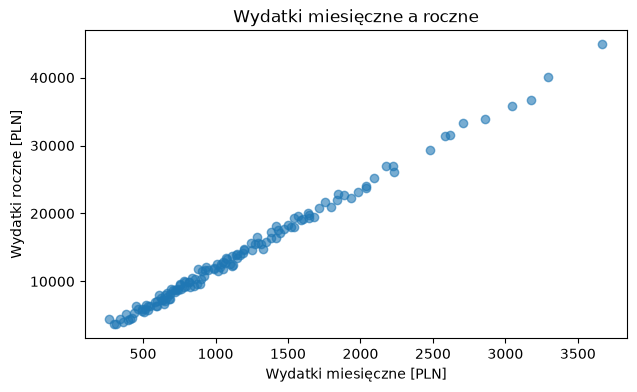

In [10]:
plt.figure(figsize=(7, 4))
plt.scatter(
    train["wydatki_mies_pln"],
    train["wydatki_roczne_pln"],
    alpha=0.6
)
plt.xlabel("Wydatki miesięczne [PLN]")
plt.ylabel("Wydatki roczne [PLN]")
plt.title("Wydatki miesięczne a roczne")
plt.show()

Jeżeli dwie cechy są bardzo silnie skorelowane, mogą przenosić prawie tę samą informację.

W takiej sytuacji można rozważyć pozostawienie jednej z nich.  
Decyzji nie podejmujemy jednak wyłącznie na podstawie liczby — należy uwzględnić znaczenie cech.


# Część C. Mutual Information


## 8. Mutual Information i zależność nieliniowa

Porównamy:

- `wiek` — cecha związana z klasą,
- `sygnal_nieliniowy` — cecha silnie związana z klasą, ale nieliniowo,
- `losowa_numeryczna` — cecha losowa.

Mutual Information może wykrywać zależności, które nie są liniowe.


In [11]:
mi_features = [
    "wiek",
    "sygnal_nieliniowy",
    "losowa_numeryczna"
]

mi = mutual_info_classif(
    train[mi_features],
    train["segment"],
    random_state=42
)

mi_table = pd.DataFrame({
    "cecha": mi_features,
    "MI": mi
})

mi_table.sort_values("MI", ascending=False)

,cecha,MI
0,wiek,0.705805
1,sygnal_nieliniowy,0.599716
2,losowa_numeryczna,0.009376


Dla porównania policzymy korelację Pearsona z liczbowym kodem segmentu.


In [12]:
segment_code = train["segment"].map({
    "A": 0,
    "B": 1,
    "C": 2
})

print(
    "wiek:",
    round(train["wiek"].corr(segment_code), 3)
)

print(
    "sygnal_nieliniowy:",
    round(train["sygnal_nieliniowy"].corr(segment_code), 3)
)

print(
    "losowa_numeryczna:",
    round(train["losowa_numeryczna"].corr(segment_code), 3)
)

wiek: 0.89
sygnal_nieliniowy: -0.012
losowa_numeryczna: -0.079


### Jak wygląda `sygnal_nieliniowy` w poszczególnych klasach?

Wykres pudełkowy ułatwia zauważenie, że segment B ma inne wartości niż segmenty A i C.  
Jednocześnie zależność z liczbowym kodem klasy `0, 1, 2` nie jest liniowa.


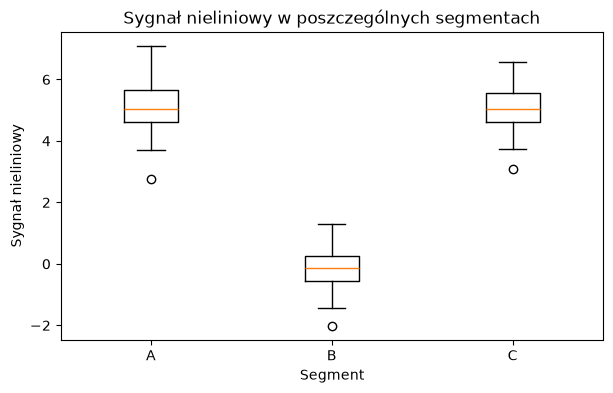

In [13]:
signal_A = train.loc[train["segment"] == "A", "sygnal_nieliniowy"]
signal_B = train.loc[train["segment"] == "B", "sygnal_nieliniowy"]
signal_C = train.loc[train["segment"] == "C", "sygnal_nieliniowy"]

plt.figure(figsize=(7, 4))
plt.boxplot(
    [signal_A, signal_B, signal_C],
    tick_labels=["A", "B", "C"]
)
plt.xlabel("Segment")
plt.ylabel("Sygnał nieliniowy")
plt.title("Sygnał nieliniowy w poszczególnych segmentach")
plt.show()

### Interpretacja

`sygnal_nieliniowy` może mieć wysoką MI, a jednocześnie korelację Pearsona bliską 0.

To pokazuje, że wartość korelacja bliska 0 nie oznacza automatycznie braku zależności między cechą a klasą.

**Uwaga:** Mutual Information daje wynik / ranking, a nie `p-value`.


# Część D. Test chi-kwadrat


## 9. Program lojalnościowy a segment

Sprawdzimy, czy `program_lojalnosci` jest zależny od klasy `segment`.

Hipotezy:

- **H₀:** cecha i klasa są niezależne,
- **H₁:** istnieje zależność między cechą i klasą.


In [14]:
table = pd.crosstab(
    train["program_lojalnosci"],
    train["segment"]
)

table

segment,A,B,C
program_lojalnosci,,,
nie,38,18,6
tak,7,27,39


### Rozkład liczności

Przed wykonaniem testu warto obejrzeć rozkład kategorii w poszczególnych klasach.


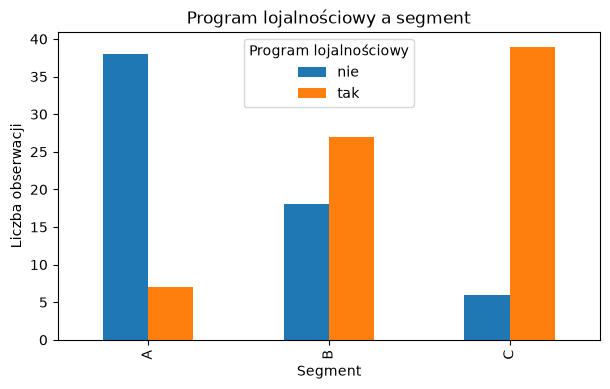

In [15]:
table.T.plot(
    kind="bar",
    figsize=(7, 4)
)
plt.xlabel("Segment")
plt.ylabel("Liczba obserwacji")
plt.title("Program lojalnościowy a segment")
plt.legend(title="Program lojalnościowy")
plt.show()

In [16]:
chi_stat, p, dof, expected = chi2_contingency(table)

print("chi2 =", round(chi_stat, 3))
print("p =", p)
print("stopnie swobody =", dof)

print("\nLiczności oczekiwane:")
print(np.round(expected, 2))

chi2 = 46.77
p = 6.983489395220902e-11
stopnie swobody = 2

Liczności oczekiwane:
[[20.67 20.67 20.67]
 [24.33 24.33 24.33]]


Jeżeli `p < 0.05`, odrzucamy H₀.

Warto również sprawdzić liczności oczekiwane.  
Przy bardzo małych licznościach przybliżenie chi-kwadrat może być niewiarygodne.


# Część E. Dwie klasy – wybór odpowiedniego testu


## 10. Schemat wyboru testu

Dla dwóch niezależnych klas na zajęciach przyjmujemy następujący schemat:

1. sprawdzamy normalność w obu grupach,
2. jeśli rozkłady są w przybliżeniu normalne – sprawdzamy wariancje,
3. podobne wariancje → test t-Studenta,
4. różne wariancje → test t Welcha,
5. wyraźny brak normalności → test U Manna–Whitneya.

Test Welcha rozwiązuje problem **nierównych wariancji**, ale nie jest automatycznym rozwiązaniem problemu wyraźnie nienormalnego rozkładu.


## 11. Przykład 1 – test t-Studenta

Porównamy `wiek` w segmentach A i B.


In [17]:
age_A = train.loc[
    train["segment"] == "A",
    "wiek"
]

age_B = train.loc[
    train["segment"] == "B",
    "wiek"
]

print("Shapiro A:", shapiro(age_A).pvalue)
print("Shapiro B:", shapiro(age_B).pvalue)

Shapiro A: 0.998828141873758
Shapiro B: 0.9998662860096019


### Wykres pudełkowy wieku w obu grupach

Wykres pomaga porównać położenie, rozrzut i ewentualne obserwacje skrajne.


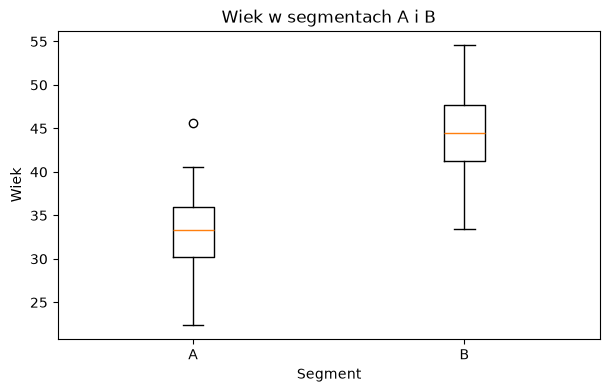

In [18]:
plt.figure(figsize=(7, 4))
plt.boxplot(
    [age_A, age_B],
    tick_labels=["A", "B"]
)
plt.xlabel("Segment")
plt.ylabel("Wiek")
plt.title("Wiek w segmentach A i B")
plt.show()

In [19]:
levene_age = levene(age_A, age_B)

print("Levene p =", levene_age.pvalue)

Levene p = 0.8591013704155683


In [20]:
result_t = ttest_ind(
    age_A,
    age_B,
    equal_var=True
)

print("t =", round(result_t.statistic, 3))
print("p =", result_t.pvalue)

t = -11.43
p = 4.421369350473493e-19


## 12. Przykład 2 – test t Welcha

`czas_obslugi_min` ma w obu grupach rozkład zbliżony do normalnego, ale wariancje różnią się.

Dlatego zastosujemy test t Welcha.


In [21]:
service_A = train.loc[
    train["segment"] == "A",
    "czas_obslugi_min"
]

service_B = train.loc[
    train["segment"] == "B",
    "czas_obslugi_min"
]

print("Shapiro A:", shapiro(service_A).pvalue)
print("Shapiro B:", shapiro(service_B).pvalue)

print(
    "Levene p =",
    levene(service_A, service_B).pvalue
)

Shapiro A: 0.9973322574735647
Shapiro B: 0.9983074285973204
Levene p = 3.364214753974352e-05


In [22]:
result_welch = ttest_ind(
    service_A,
    service_B,
    equal_var=False
)

print("t =", round(result_welch.statistic, 3))
print("p =", result_welch.pvalue)

t = -6.601
p = 1.1212220615833816e-08


### Uwaga praktyczna dotycząca testu Welcha

W praktyce statystycznej często zaleca się stosowanie **testu Welcha jako domyślnego testu porównującego dwie średnie**, zamiast najpierw wykonywać osobny test równości wariancji i dopiero na jego podstawie wybierać wersję testu t.

Na tych zajęciach rozdzielamy te przypadki celowo, aby przećwiczyć znaczenie założeń poszczególnych testów.


## 13. Przykład 3 – test U Manna–Whitneya

`dochod_mies_pln` ma rozkład skośny.  
Najpierw sprawdzimy normalność.


In [23]:
income_A = train.loc[
    train["segment"] == "A",
    "dochod_mies_pln"
]

income_B = train.loc[
    train["segment"] == "B",
    "dochod_mies_pln"
]

print("Shapiro A:", shapiro(income_A).pvalue)
print("Shapiro B:", shapiro(income_B).pvalue)

Shapiro A: 0.0005242244427078706
Shapiro B: 0.0026435848386489997


### Histogram dochodu

Histogram pokazuje prawoskośny charakter zmiennej.  
Jest to dodatkowa informacja obok testu Shapiro–Wilka.


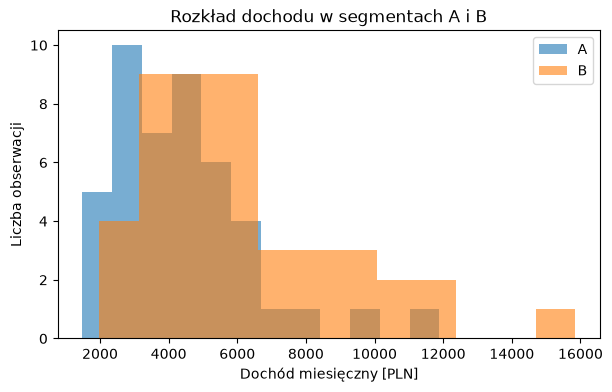

In [24]:
plt.figure(figsize=(7, 4))
plt.hist(income_A, bins=12, alpha=0.6, label="A")
plt.hist(income_B, bins=12, alpha=0.6, label="B")
plt.xlabel("Dochód miesięczny [PLN]")
plt.ylabel("Liczba obserwacji")
plt.title("Rozkład dochodu w segmentach A i B")
plt.legend()
plt.show()

In [25]:
result_u = mannwhitneyu(
    income_A,
    income_B,
    alternative="two-sided"
)

print("U =", result_u.statistic)
print("p =", result_u.pvalue)

U = 592.0
p = 0.0007007790163982223


### Uwaga interpretacyjna

Test U Manna–Whitneya wykorzystuje rangi i porównuje położenie / rozkłady dwóch niezależnych grup.

Nie zawsze należy opisywać go po prostu jako „test median”.  
Taka interpretacja wymaga dodatkowych założeń, m.in. podobnego kształtu rozkładów.


# Część F. Więcej niż dwie klasy


## 14. ANOVA

Dla `wynik_oceny` sprawdzimy trzy segmenty: A, B i C.

Najpierw sprawdzamy założenia.


In [26]:
score_A = train.loc[
    train["segment"] == "A",
    "wynik_oceny"
]

score_B = train.loc[
    train["segment"] == "B",
    "wynik_oceny"
]

score_C = train.loc[
    train["segment"] == "C",
    "wynik_oceny"
]

print("Shapiro A:", shapiro(score_A).pvalue)
print("Shapiro B:", shapiro(score_B).pvalue)
print("Shapiro C:", shapiro(score_C).pvalue)

print(
    "Levene:",
    levene(score_A, score_B, score_C).pvalue
)

Shapiro A: 0.9986334199022902
Shapiro B: 0.9999284616252699
Shapiro C: 0.9986029924160829
Levene: 0.6558233271524001


### Wykres pudełkowy przed ANOVA

Wykres pozwala porównać położenie i rozrzut wyniku w trzech segmentach.


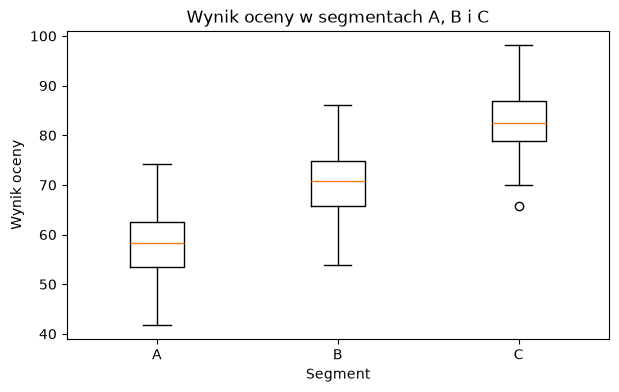

In [27]:
plt.figure(figsize=(7, 4))
plt.boxplot(
    [score_A, score_B, score_C],
    tick_labels=["A", "B", "C"]
)
plt.xlabel("Segment")
plt.ylabel("Wynik oceny")
plt.title("Wynik oceny w segmentach A, B i C")
plt.show()

In [28]:
anova_result = f_oneway(
    score_A,
    score_B,
    score_C
)

print("F =", round(anova_result.statistic, 3))
print("p =", anova_result.pvalue)

F = 134.982
p = 1.2064714137643593e-32


### Test post-hoc po ANOVA

Jeżeli wynik ANOVA jest istotny (`p < 0.05`), wiemy jedynie, że co najmniej jedna średnia różni się od pozostałych.

Aby ustalić, które pary grup różnią się między sobą, wykonujemy test Tukeya HSD.


In [29]:
if anova_result.pvalue < 0.05:
    tukey = pairwise_tukeyhsd(
        endog=train["wynik_oceny"],
        groups=train["segment"],
        alpha=0.05
    )
    print(tukey)
else:
    print("ANOVA nie jest istotna - nie wykonujemy testu post-hoc.")

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
     A      B  12.3933   0.0  8.8724 15.9143   True
     A      C  24.4044   0.0 20.8835 27.9254   True
     B      C  12.0111   0.0  8.4901 15.5321   True
---------------------------------------------------


Hipotezy ANOVA:

- **H₀:** wszystkie średnie są równe,
- **H₁:** co najmniej jedna średnia jest inna.

Istotny wynik ANOVA nie mówi jeszcze, które pary grup różnią się między sobą.


## 15. Test Kruskala–Wallisa

`czas_na_stronie_min` ma rozkład wyraźnie skośny.

Sprawdzimy trzy grupy.


In [30]:
time_A = train.loc[
    train["segment"] == "A",
    "czas_na_stronie_min"
]

time_B = train.loc[
    train["segment"] == "B",
    "czas_na_stronie_min"
]

time_C = train.loc[
    train["segment"] == "C",
    "czas_na_stronie_min"
]

print("Shapiro A:", shapiro(time_A).pvalue)
print("Shapiro B:", shapiro(time_B).pvalue)
print("Shapiro C:", shapiro(time_C).pvalue)

Shapiro A: 6.970776089392011e-05
Shapiro B: 7.043976129310371e-07
Shapiro C: 4.462659162329713e-06


### Wykres pudełkowy przed testem Kruskala–Wallisa

Wykres pokazuje rozkład wartości w trzech grupach i ułatwia ocenę różnic między nimi.


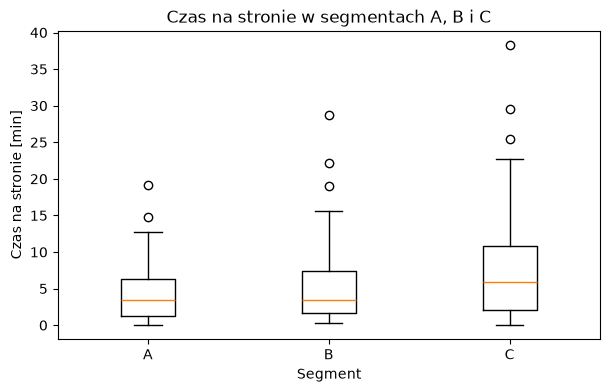

In [31]:
plt.figure(figsize=(7, 4))
plt.boxplot(
    [time_A, time_B, time_C],
    tick_labels=["A", "B", "C"]
)
plt.xlabel("Segment")
plt.ylabel("Czas na stronie [min]")
plt.title("Czas na stronie w segmentach A, B i C")
plt.show()

In [32]:
kw_result = kruskal(
    time_A,
    time_B,
    time_C
)

print("H =", round(kw_result.statistic, 3))
print("p =", kw_result.pvalue)

H = 3.994
p = 0.13571399706642148


### Analiza post-hoc po teście Kruskala–Wallisa

Jeżeli wynik testu Kruskala–Wallisa jest istotny (`p < 0.05`), test globalny nie wskazuje jeszcze, **które pary grup różnią się między sobą**.

Wykonujemy trzy porównania parami testem U Manna–Whitneya i stosujemy korektę Bonferroniego:

`p_skorygowane = min(3 * p, 1)`

Porównujemy: A–B, A–C oraz B–C.


In [33]:
if kw_result.pvalue < 0.05:
    ab = mannwhitneyu(time_A, time_B, alternative="two-sided")
    ac = mannwhitneyu(time_A, time_C, alternative="two-sided")
    bc = mannwhitneyu(time_B, time_C, alternative="two-sided")

    posthoc_kw = pd.DataFrame({
        "porownanie": ["A - B", "A - C", "B - C"],
        "U": [ab.statistic, ac.statistic, bc.statistic],
        "p": [ab.pvalue, ac.pvalue, bc.pvalue]
    })

    posthoc_kw["p_Bonferroni"] = np.minimum(
        posthoc_kw["p"] * 3,
        1.0
    )

    posthoc_kw["istotne_0.05"] = (
        posthoc_kw["p_Bonferroni"] < 0.05
    )

    display(posthoc_kw)
else:
    print("Test Kruskala-Wallisa nie jest istotny - nie wykonujemy post-hoc.")

Test Kruskala-Wallisa nie jest istotny - nie wykonujemy post-hoc.


# Część G. Zadania do samodzielnego wykonania

## Zadanie 1. Wariancja po sprowadzeniu cech do wspólnej skali

Dla cech:

- `satysfakcja`,
- `wynik_oceny`,
- `cecha_prawie_stala`

wykonaj:

1. `MinMaxScaler` dopasowany tylko na treningu,
2. oblicz wariancję cech po skalowaniu,
3. zastosuj `VarianceThreshold(threshold=0.02)`,
4. wypisz nazwę usuniętej cechy.

Na końcu odpowiedz:

Dlaczego `StandardScaler` nie byłby dobrym wyborem przed takim progiem wariancji?


In [52]:
# TODO - Zadanie 1
features = ["satysfakcja", "wynik_oceny", "cecha_prawie_stala"]

minmax = MinMaxScaler()
train_mm = minmax.fit_transform(df[features])
test_mm = minmax.transform(df[features])

scaled_df = pd.DataFrame(train_mm, columns=features)
print(scaled_df.var())

selector = VarianceThreshold(threshold=0.02)

selector.fit(scaled_df)

print("Pozostawione cechy:")
print(np.array(features_var)[selector.get_support()])

print("Usunięte cechy:")
print(np.array(features_var)[~selector.get_support()])

satysfakcja           0.035853
wynik_oceny           0.045129
cecha_prawie_stala    0.016480
dtype: float64
Pozostawione cechy:
['wiek' 'dochod_mies_pln']
Usunięte cechy:
['cecha_stala']


## Zadanie 2.

Sprawdź zależność pomiędzy:

- `wizyty_mies`,
- `wizyty_kwartal`.

1. Narysuj wykres punktowy obu cech.
2. Oblicz współczynnik korelacji Pearsona.
3. Oceń, czy cechy są redundantne.
4. Zdecyduj, którą z nich można rozważyć do usunięcia.
5. Uzasadnij decyzję znaczeniem cech.


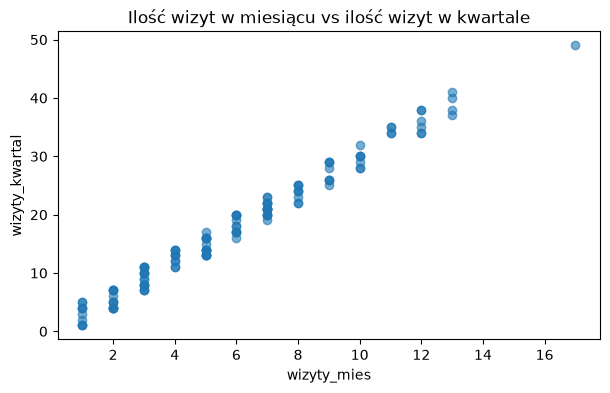

wizyty_mies: 0.715
wizyty_kwartal: 0.704


In [56]:
# TODO - Zadanie 2
corr = train[
    [
        "wizyty_mies",
        "wizyty_kwartal",
    ]
].corr()

corr.round(3)

plt.figure(figsize=(7, 4))
plt.scatter(
    train["wizyty_mies"],
    train["wizyty_kwartal"],
    alpha=0.6
)
plt.xlabel("wizyty_mies")
plt.ylabel("wizyty_kwartal")
plt.title("Ilość wizyt w miesiącu vs ilość wizyt w kwartale")
plt.show()

segment_code = train["segment"].map({
    "A": 0,
    "B": 1,
    "C": 2
})

print(
    "wizyty_mies:",
    round(train["wizyty_mies"].corr(segment_code), 3)
)

print(
    "wizyty_kwartal:",
    round(train["wizyty_kwartal"].corr(segment_code), 3)
)

## Zadanie 3.

Oblicz MI dla:

- `wynik_oceny`,
- `czas_obslugi_min`,
- `wydatki_mies_pln`,
- `losowa_numeryczna_2`.

1. Utwórz tabelę `cecha – MI`.
2. Posortuj ją malejąco.
3. Wskaż dwie najwyżej ocenione cechy.
4. Wyjaśnij, dlaczego nie stosujemy tutaj reguły `p < 0.05`.


In [55]:
# TODO - Zadanie 3

mi_features = [
    "wynik_oceny",
    "czas_obslugi_min",
    "wydatki_mies_pln",
    "losowa_numeryczna_2"
]

mi = mutual_info_classif(
    train[mi_features],
    train["segment"],
    random_state=42
)

mi_table = pd.DataFrame({
    "cecha": mi_features,
    "MI": mi
})

mi_table.sort_values("MI", ascending=False)


,cecha,MI
0,wynik_oceny,0.482234
1,czas_obslugi_min,0.327610
2,wydatki_mies_pln,0.039133
3,losowa_numeryczna_2,0.000000


## Zadanie 4.

Sprawdź zależność między:

- `kanal`,
- `segment`.

Wykonaj:

1. tabelę częstości,
2. test chi-kwadrat,
3. sprawdzenie liczności oczekiwanych,
4. interpretację przy poziomie istotności `α = 0.05`.

Na końcu odpowiedz, czy `kanal` jest kandydatem do pozostawienia w zbiorze cech.


In [61]:
# TODO - Zadanie 4
table = pd.crosstab(
    train["kanal"],
    train["segment"]
)

print(table)

chi_stat, p, dof, expected = chi2_contingency(table)

print("\nchi2 =", round(chi_stat, 3))
print("p =", p)
print("stopnie swobody =", dof)

print("\nLiczności oczekiwane:")
print(np.round(expected, 2))

segment     A   B   C
kanal                
Aplikacja  15  23  16
Sklep       4   7  16
WWW        26  15  13

chi2 = 16.222
p = 0.0027350202443401157
stopnie swobody = 4

Liczności oczekiwane:
[[18. 18. 18.]
 [ 9.  9.  9.]
 [18. 18. 18.]]


## Zadanie 5.

Porównaj `satysfakcja` między segmentami A i B.

Nie podano, jakiego testu użyć.

1. Narysuj wykres pudełkowy dla obu grup.
2. Sprawdź normalność w obu grupach.
3. Jeżeli można rozważać test parametryczny, sprawdź wariancje.
4. Wybierz odpowiedni test.
5. Wykonaj go.
6. Uzasadnij wybór.


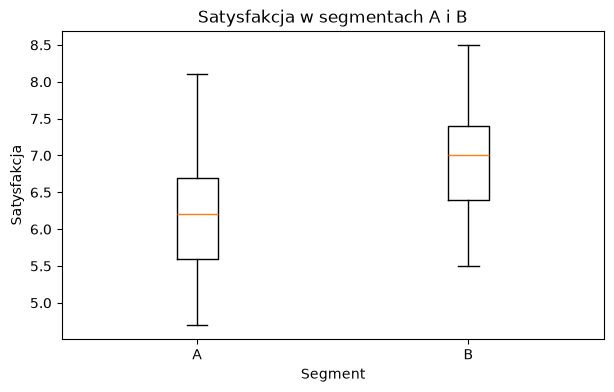

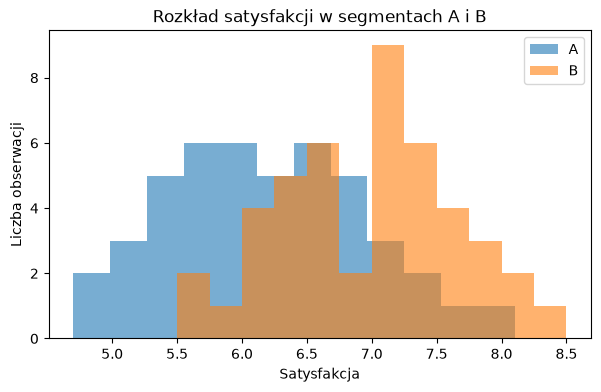

In [66]:
# TODO - Zadanie 5

satysfaction_A = train.loc[
    train["segment"] == "A",
    "satysfakcja"
]

satysfaction_B = train.loc[
    train["segment"] == "B",
    "satysfakcja"
]

plt.figure(figsize=(7, 4))
plt.boxplot(
    [satysfaction_A, satysfaction_B],
    tick_labels=["A", "B"]
)
plt.xlabel("Segment")
plt.ylabel("Satysfakcja")
plt.title("Satysfakcja w segmentach A i B")
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(satysfaction_A, bins=12, alpha=0.6, label="A")
plt.hist(satysfaction_B, bins=12, alpha=0.6, label="B")
plt.xlabel("Satysfakcja")
plt.ylabel("Liczba obserwacji")
plt.title("Rozkład satysfakcji w segmentach A i B")
plt.legend()
plt.show()


## Zadanie 6.

Porównaj `wydatki_mies_pln` między segmentami A i B.

1. Narysuj histogram zmiennej w obu grupach.
2. Sprawdź normalność.
3. Wybierz właściwy test.
4. Wykonaj test.
5. Oceń, czy cecha różnicuje grupy na poziomie `α = 0.05`.

Nie zakładaj z góry, że należy zastosować test t.


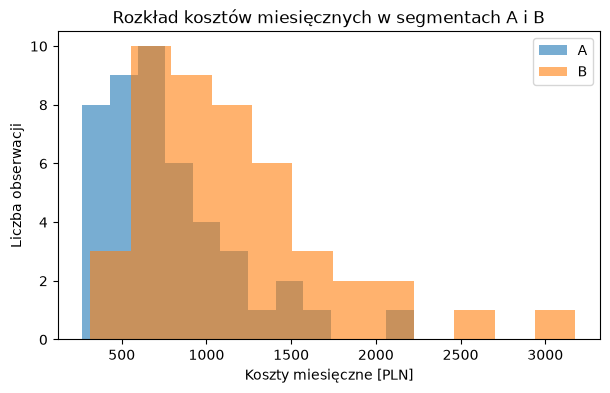

In [67]:
# TODO - Zadanie 6

cost_A = train.loc[
    train["segment"] == "A",
    "wydatki_mies_pln"
]

cost_B = train.loc[
    train["segment"] == "B",
    "wydatki_mies_pln"
]

plt.figure(figsize=(7, 4))
plt.hist(cost_A, bins=12, alpha=0.6, label="A")
plt.hist(cost_B, bins=12, alpha=0.6, label="B")
plt.xlabel("Koszty miesięczne [PLN]")
plt.ylabel("Liczba obserwacji")
plt.title("Rozkład kosztów miesięcznych w segmentach A i B")
plt.legend()
plt.show()

## Zadanie 7. 

Porównaj `satysfakcja` między segmentami A, B i C.

1. Narysuj wykres pudełkowy dla trzech grup.
2. Sprawdź normalność w każdej grupie.
3. Sprawdź jednorodność wariancji.
4. Wybierz ANOVA albo test Kruskala–Wallisa.
5. Wykonaj wybrany test.
6. Jeżeli `p < 0.05`, wykonaj odpowiednią analizę post-hoc.
7. Zinterpretuj wynik.


In [40]:
# TODO - Zadanie 7


## Zadanie 8. 

Porównaj `wydatki_mies_pln` między segmentami A, B i C.

1. Narysuj wykres pokazujący rozkład cechy w trzech grupach.
2. Sprawdź normalność w każdej grupie.
3. Wybierz właściwy test.
4. Wykonaj go.
5. Jeżeli wynik jest istotny (`p < 0.05`), wykonaj porównania parami i zastosuj korektę na wielokrotne porównania.
6. Zinterpretuj wyniki.

Pamiętaj, że istotny wynik dla trzech grup nie wskazuje automatycznie, które konkretne pary grup różnią się między sobą.


In [41]:
# TODO - Zadanie 8


## Zadanie dodatkowe. Końcowa decyzja o zestawie cech

Na podstawie wyników z zajęć zaproponuj, które cechy z poniższej listy pozostawił(a)byś do dalszego modelowania:

- `cecha_stala`,
- `wydatki_mies_pln`,
- `wydatki_roczne_pln`,
- `wizyty_mies`,
- `wizyty_kwartal`,
- `sygnal_nieliniowy`,
- `losowa_numeryczna`,
- `program_lojalnosci`.

Dla każdej odrzuconej cechy podaj **krótkie uzasadnienie**.

Nie istnieje jedna mechaniczna reguła — uwzględnij wyniki metod selekcji i znaczenie cech.


# Podsumowanie

Najważniejsze zasady:

- cecha stała nie wnosi informacji do klasyfikacji,
- przy progu wariancji większym od zera należy uwzględnić skalę cech,
- standaryzacja do wariancji 1 nie powinna poprzedzać selekcji opartej na różnicach wariancji,
- wysoka korelacja może wskazywać redundancję,
- Mutual Information potrafi wykrywać zależności nieliniowe,
- Mutual Information nie zwraca `p-value`,
- chi-kwadrat służy do badania zależności cech jakościowych / dyskretnych od klasy,
- test t-Studenta wymaga innych założeń niż test Welcha,
- przy wyraźnym braku normalności można wykorzystać testy nieparametryczne,
- ANOVA i Kruskal–Wallis odpowiadają na pytanie o różnice między co najmniej trzema grupami,
- po istotnym wyniku testu globalnego wykonujemy analizę post-hoc, aby ustalić, które grupy się różnią,
- wykresy pomagają ocenić kształt rozkładu, rozrzut, obserwacje skrajne i relacje między cechami,
- istotny wynik testu statystycznego nie jest tym samym co „ważność cechy dla każdego modelu”,
- wszystkie etapy selekcji powinny być dopasowane na danych treningowych.


# Literatura i materiały

Materiał przygotowano na podstawie wykładu oraz książek dostępnych w projekcie **Uczenie maszynowe 1**:

- **Pang-Ning Tan, Michael Steinbach, Anuj Karpatne, Vipin Kumar**, *Introduction to Data Mining*, 2nd ed., Pearson, 2018.
- **Charu C. Aggarwal**, *Data Mining: The Textbook*, Springer, 2015.
- **Christian Heumann, Michael Schomaker, Shalabh**, *Introduction to Statistics and Data Analysis*, Springer International Publishing, 2016.
- **Richard M. Heiberger, Burt Holland**, *Statistical Analysis and Data Display*, 2nd ed., Springer, 2015.